In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [2]:
df = pd.read_csv("Student_Performance (1).csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


| Column                             | Explanation                                                                                                              | Example  |
| ---------------------------------- | ------------------------------------------------------------------------------------------------------------------------ | -------- |
| `Hours Studied`                    | Number of hours a student spends studying.                                                                               | 7 hours  |
| `Previous Scores`                  | The student's scores in previous exams.                                                                                  | 99 marks |
| `Extracurricular Activities`       | Indicates whether the student participates in activities outside regular studies.                                        | Yes / No |
| `Sleep Hours`                      | Number of hours the student sleeps per day.                                                                              | 9 hours  |
| `Sample Question Papers Practiced` | Number of practice exam papers the student has solved.                                                                   | 5 papers |
| `Performance Index`                | A numerical score representing the student's overall academic performance. This is the target column we want to predict. | 91       |

In Machine Learning:

* Features (X): All columns except `Performance Index`.

* Target (y): `Performance Index`.

* Problem type: Regression, because the target is a numerical value.


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [4]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [5]:
df.shape

(10000, 6)

In [6]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [7]:
df.duplicated().sum()

np.int64(132)

In [8]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True ,inplace=True)

In [9]:
df.isna().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1563
Sleep Hours                            0
Sample Question Papers Practiced    2778
Performance Index                      0
dtype: int64

In [10]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df[['Extracurricular Activities']] = imputer.fit_transform(df[['Extracurricular Activities']])

In [11]:
df['Sample Question Papers Practiced'].skew()

np.float64(-0.04148768921377276)

In [12]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df[['Sample Question Papers Practiced']] = imputer.fit_transform(df[['Sample Question Papers Practiced']])

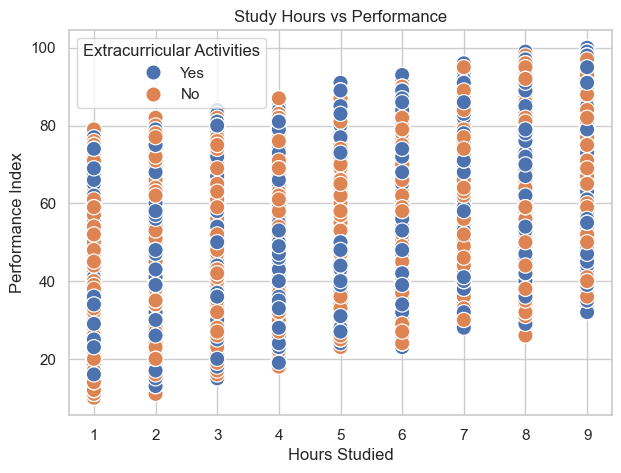

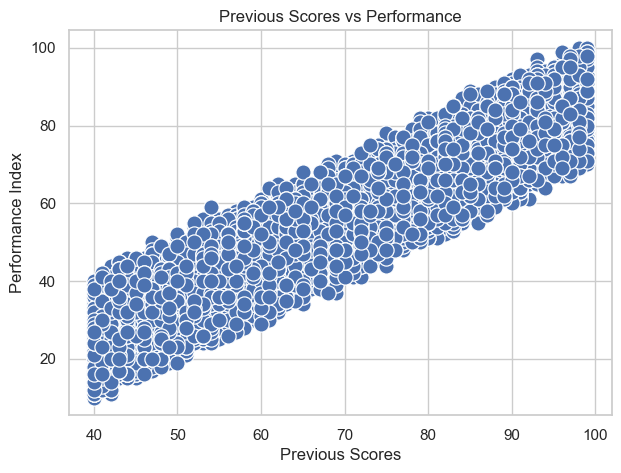

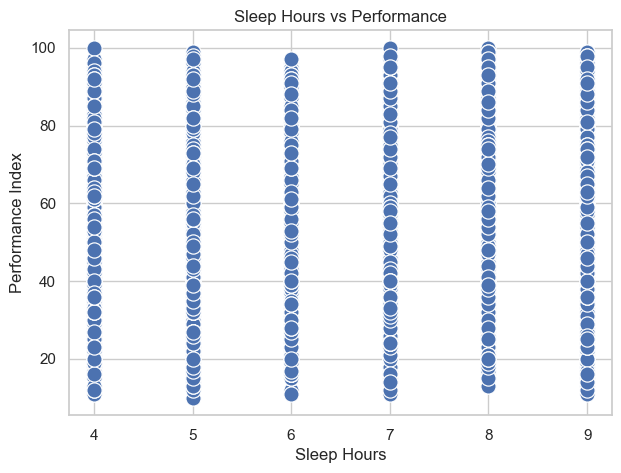

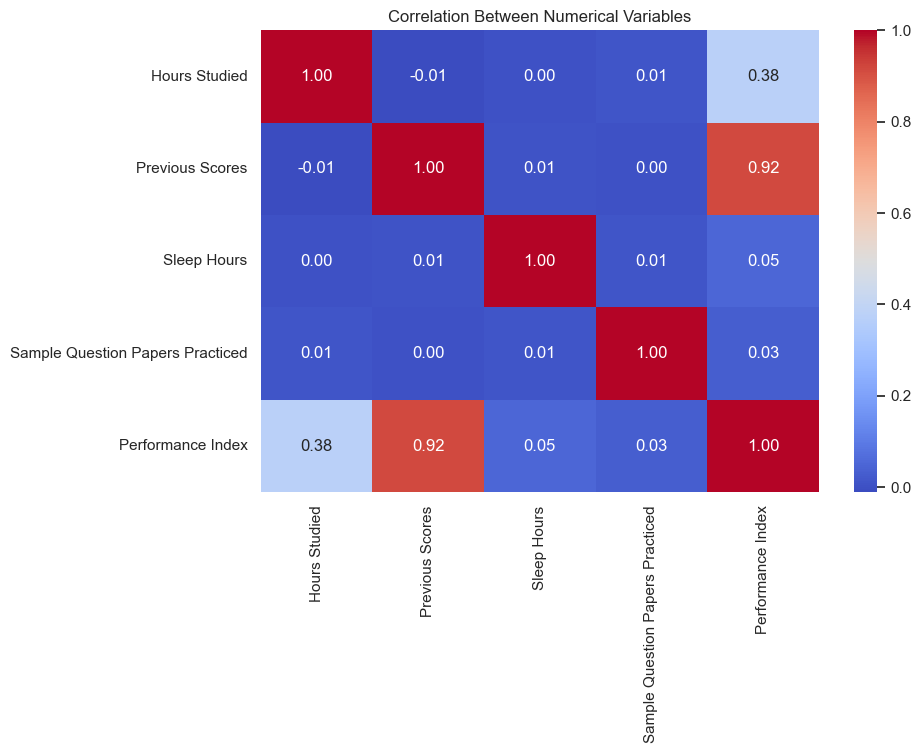

In [13]:
import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df, x="Hours Studied",
    y="Performance Index", hue="Extracurricular Activities",
    s=120
)
plt.title("Study Hours vs Performance")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df, x="Previous Scores",
    y="Performance Index", s=120
)
plt.title("Previous Scores vs Performance")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df, x="Sleep Hours",
    y="Performance Index", s=120
)
plt.title("Sleep Hours vs Performance")
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Between Numerical Variables")
plt.show()

In [14]:
df.select_dtypes(include=['object']).nunique()

Extracurricular Activities    2
dtype: int64

In [15]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Extracurricular Activities'] = le.fit_transform(df['Extracurricular Activities'])

In [16]:
x=df.drop(['Performance Index'],axis=1)
y=df['Performance Index']
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x,y,
                                   test_size= 0.20, random_state=100, stratify=None)

print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (7894, 5)  y_train =  (7894,)
X_test  =  (1974, 5)  y_test  =  (1974,)


In [17]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [18]:
y_pred=lr.predict(X_test)

In [19]:
lr.score(X_train, y_train)

0.9884836059403501

In [20]:
lr.score(X_test, y_test)

0.987908606369405

In [21]:
from  sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score
print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("RMSE : ",root_mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  1.6821644500044088
MSE :  4.505029063690512
RMSE :  2.122505374243022
R2 :  0.987908606369405


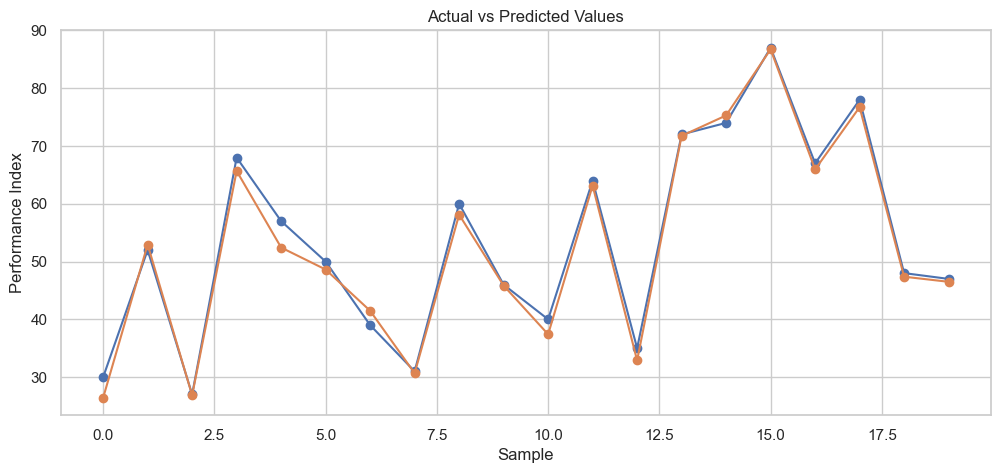

In [22]:

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(y_pred[:20], marker='o', label='Predicted')

plt.xlabel('Sample')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted Values')

plt.show()


In [23]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [24]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

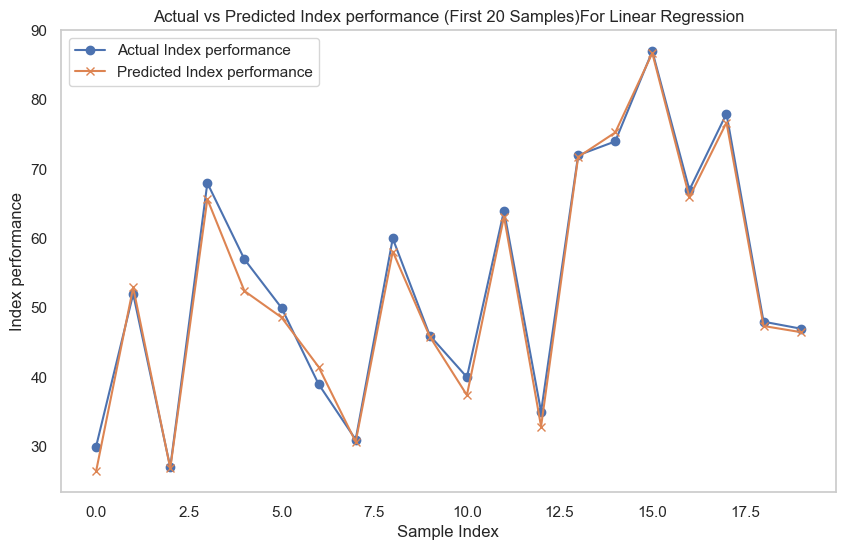

  7%|▋         | 1/15 [00:00<00:07,  1.94it/s]

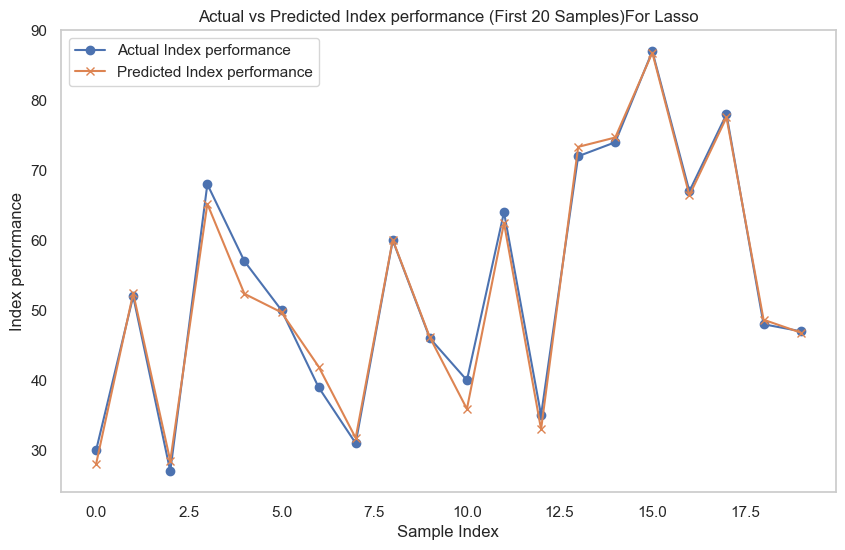

 13%|█▎        | 2/15 [00:00<00:04,  2.68it/s]

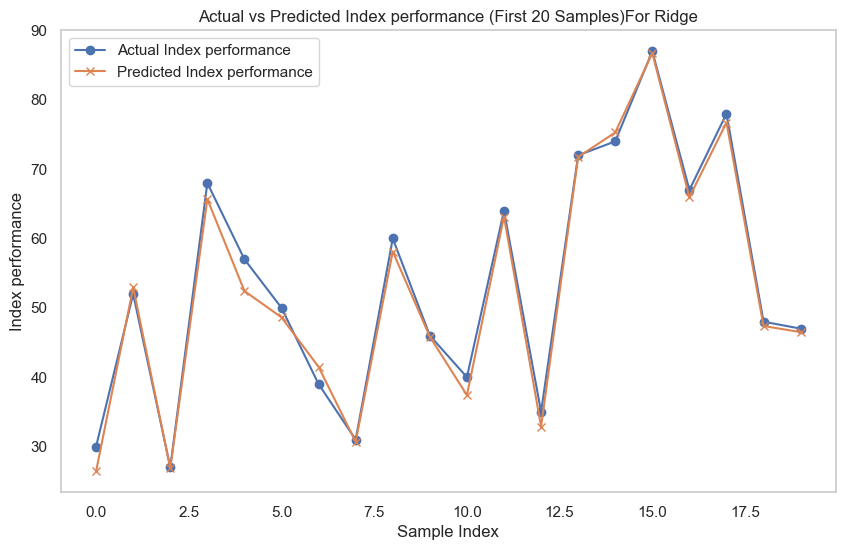

 20%|██        | 3/15 [00:01<00:05,  2.02it/s]

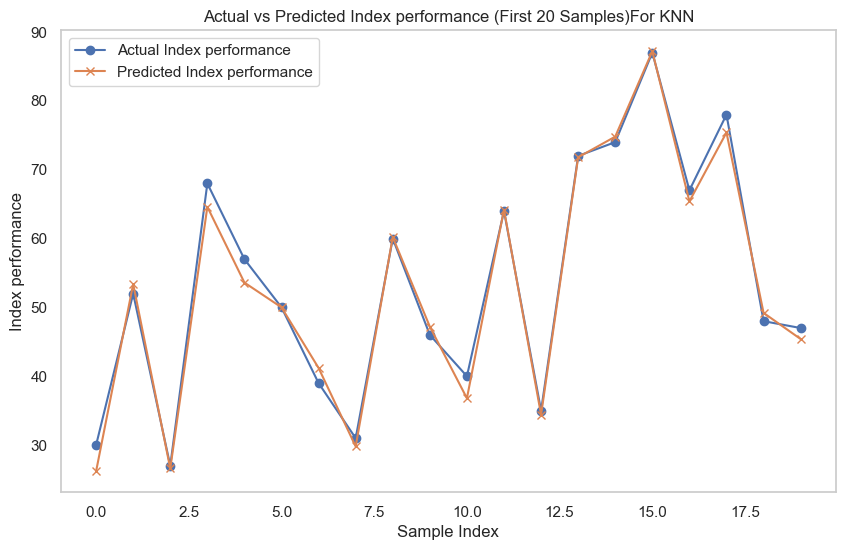

 27%|██▋       | 4/15 [00:01<00:05,  2.00it/s]

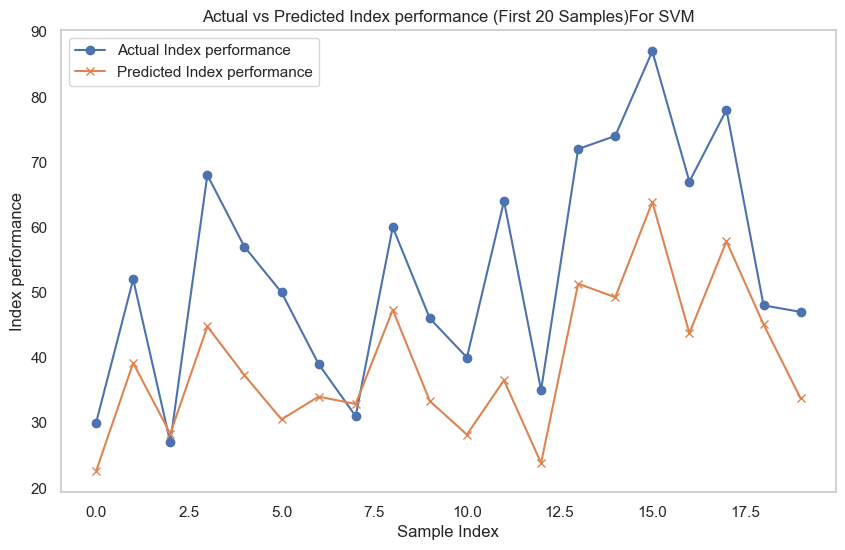

 33%|███▎      | 5/15 [04:26<15:55, 95.56s/it]

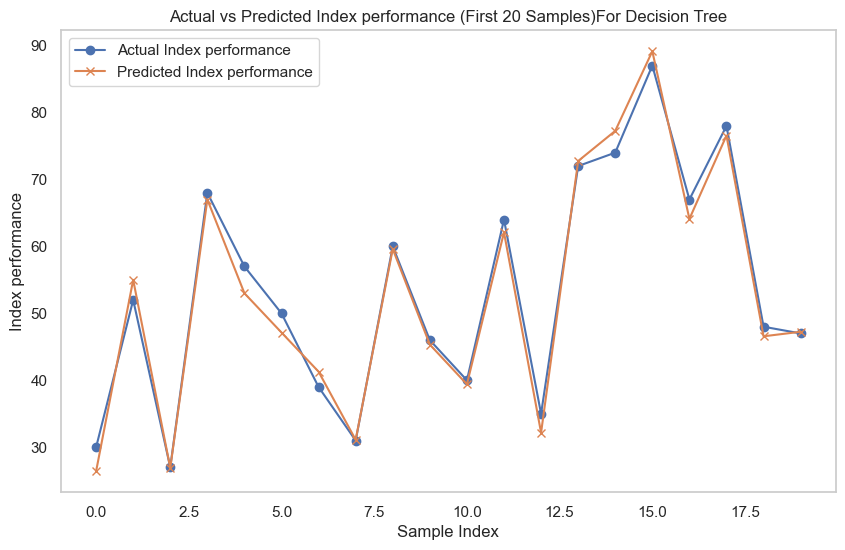

 40%|████      | 6/15 [04:26<09:29, 63.25s/it]

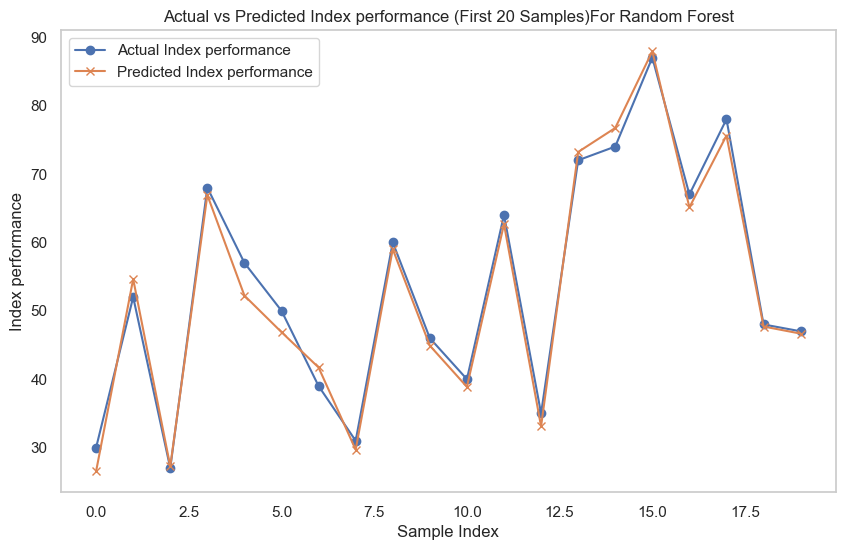

 47%|████▋     | 7/15 [04:28<05:45, 43.21s/it]

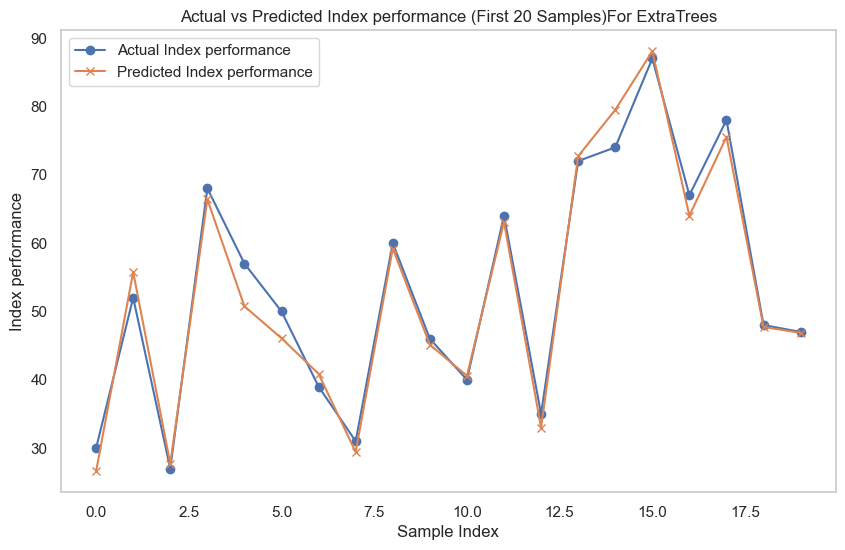

 53%|█████▎    | 8/15 [04:32<03:35, 30.81s/it]

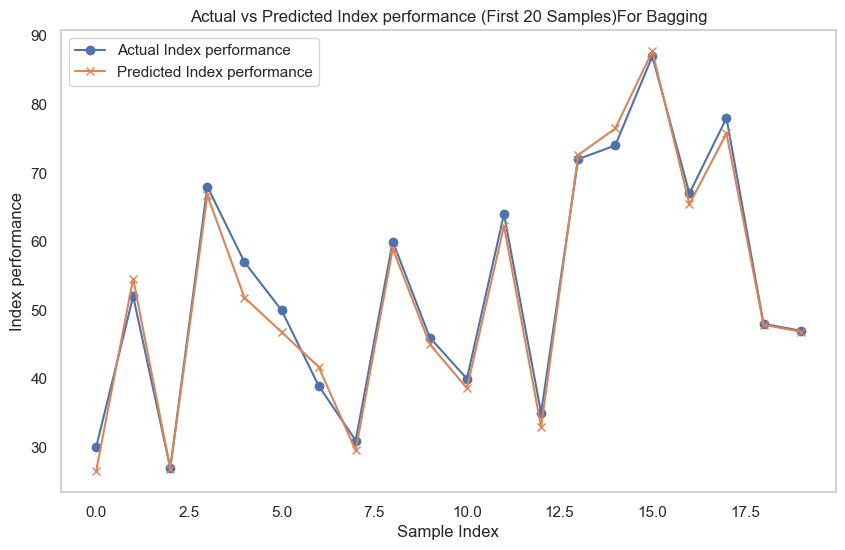

 60%|██████    | 9/15 [04:34<02:11, 21.84s/it]

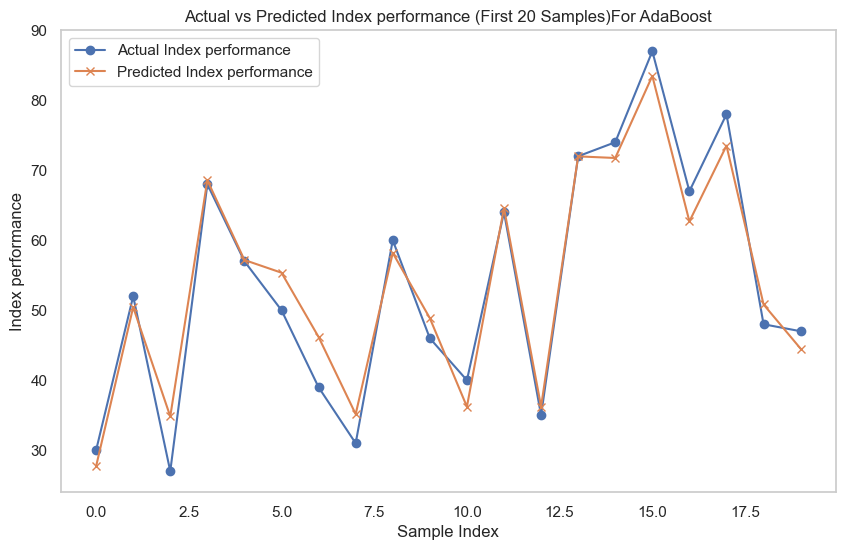

 67%|██████▋   | 10/15 [04:35<01:16, 15.33s/it]

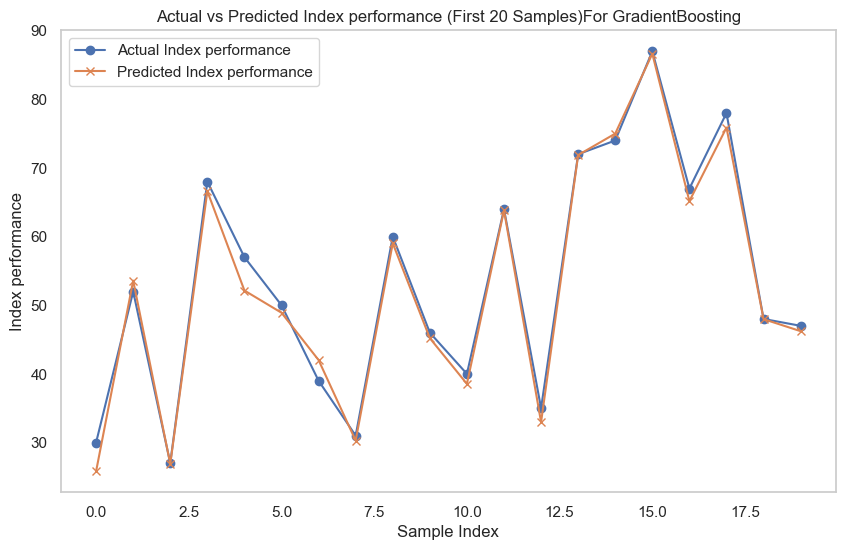

 73%|███████▎  | 11/15 [04:37<00:44, 11.05s/it]

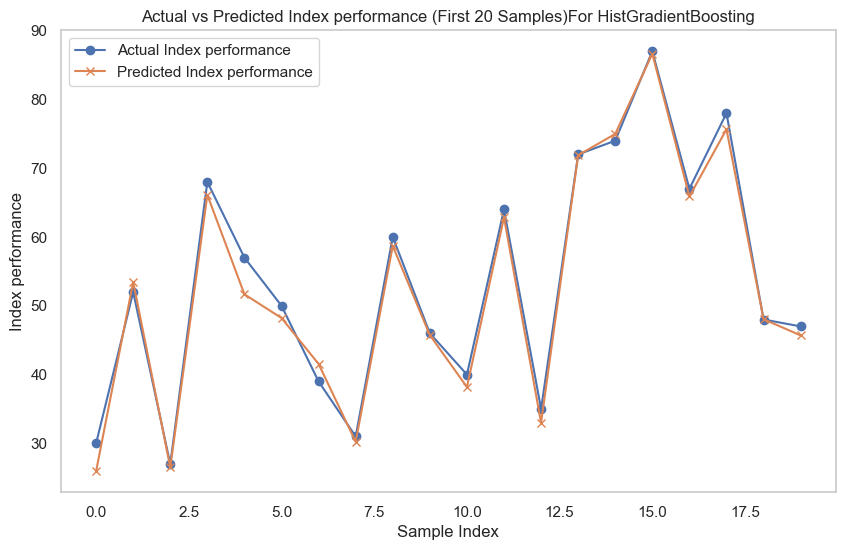

 80%|████████  | 12/15 [04:38<00:24,  8.03s/it]

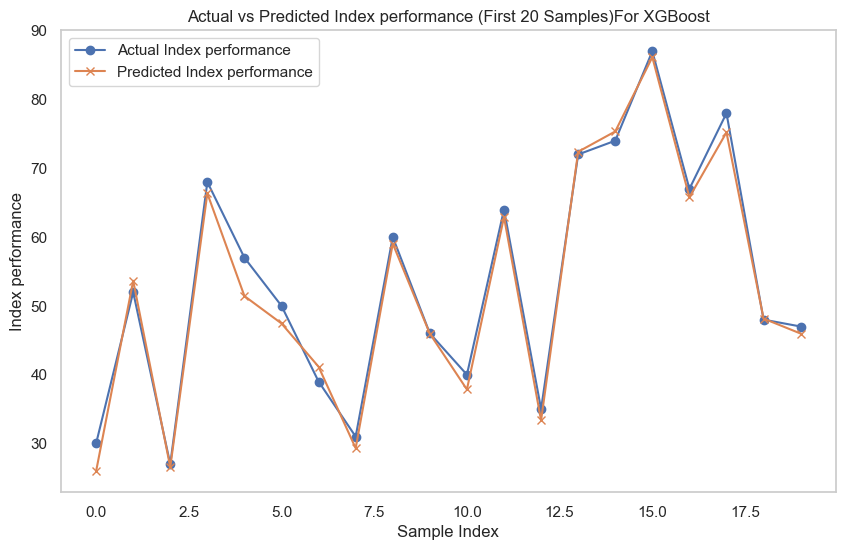

 87%|████████▋ | 13/15 [04:38<00:11,  5.78s/it]

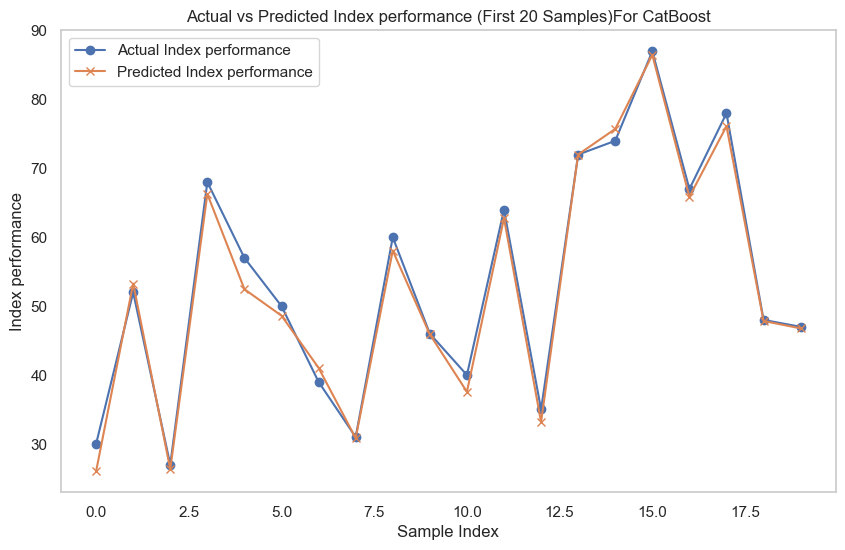

 93%|█████████▎| 14/15 [04:39<00:04,  4.39s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000383 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 91
[LightGBM] [Info] Number of data points in the train set: 7894, number of used features: 5
[LightGBM] [Info] Start training from score 55.334178


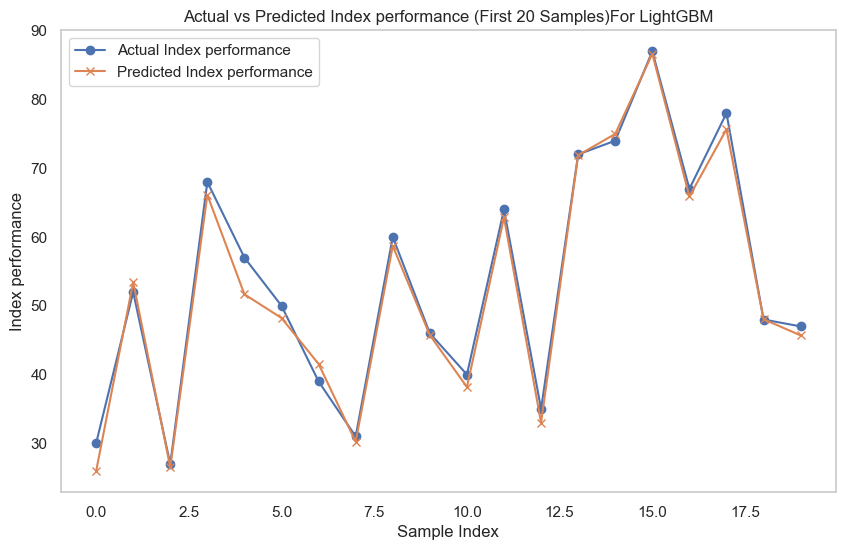

100%|██████████| 15/15 [04:40<00:00, 18.72s/it]


In [25]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Index performance', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Index performance', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Index performance')
    plt.title('Actual vs Predicted Index performance (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [26]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [27]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [28]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Ridge,1.637415,1.682157,4.243204,4.504985,2.059904,2.122495,0.988484,0.987909
Linear Regression,1.637413,1.682164,4.243204,4.505029,2.059904,2.122505,0.988484,0.987909
CatBoost,1.635167,1.704982,4.210837,4.691864,2.052032,2.166071,0.988571,0.987407
HistGradientBoosting,1.529951,1.725112,3.688398,4.769286,1.920520,2.183869,0.989989,0.987199
LightGBM,1.529951,1.725148,3.688398,4.769348,1.920520,2.183884,0.989989,0.987199
GradientBoosting,1.639898,1.723764,4.233122,4.780867,2.057455,2.186519,0.988511,0.987168
XGBoost,1.456169,1.751291,3.355989,4.852299,1.831936,2.202793,0.990892,0.986977
Lasso,1.774090,1.787927,4.971605,5.066797,2.229710,2.250955,0.986507,0.986401
Stacking,1.609973,1.725148,4.310019,4.769348,2.076059,2.183884,0.988302,0.985903
Bagging,1.318354,1.828048,2.706165,5.270063,1.645043,2.295662,0.992655,0.985855


<Axes: >

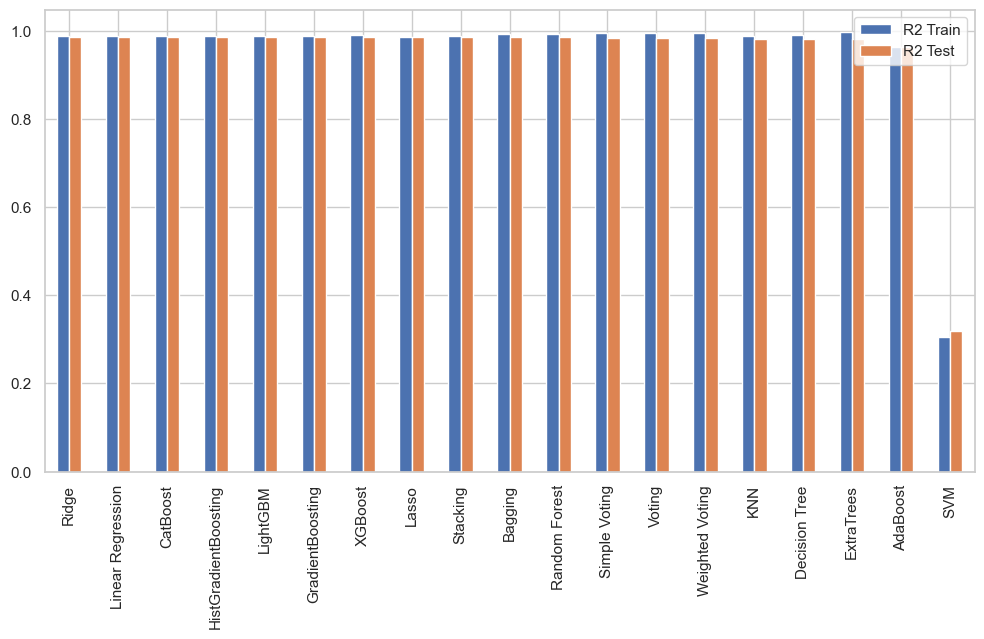

In [29]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

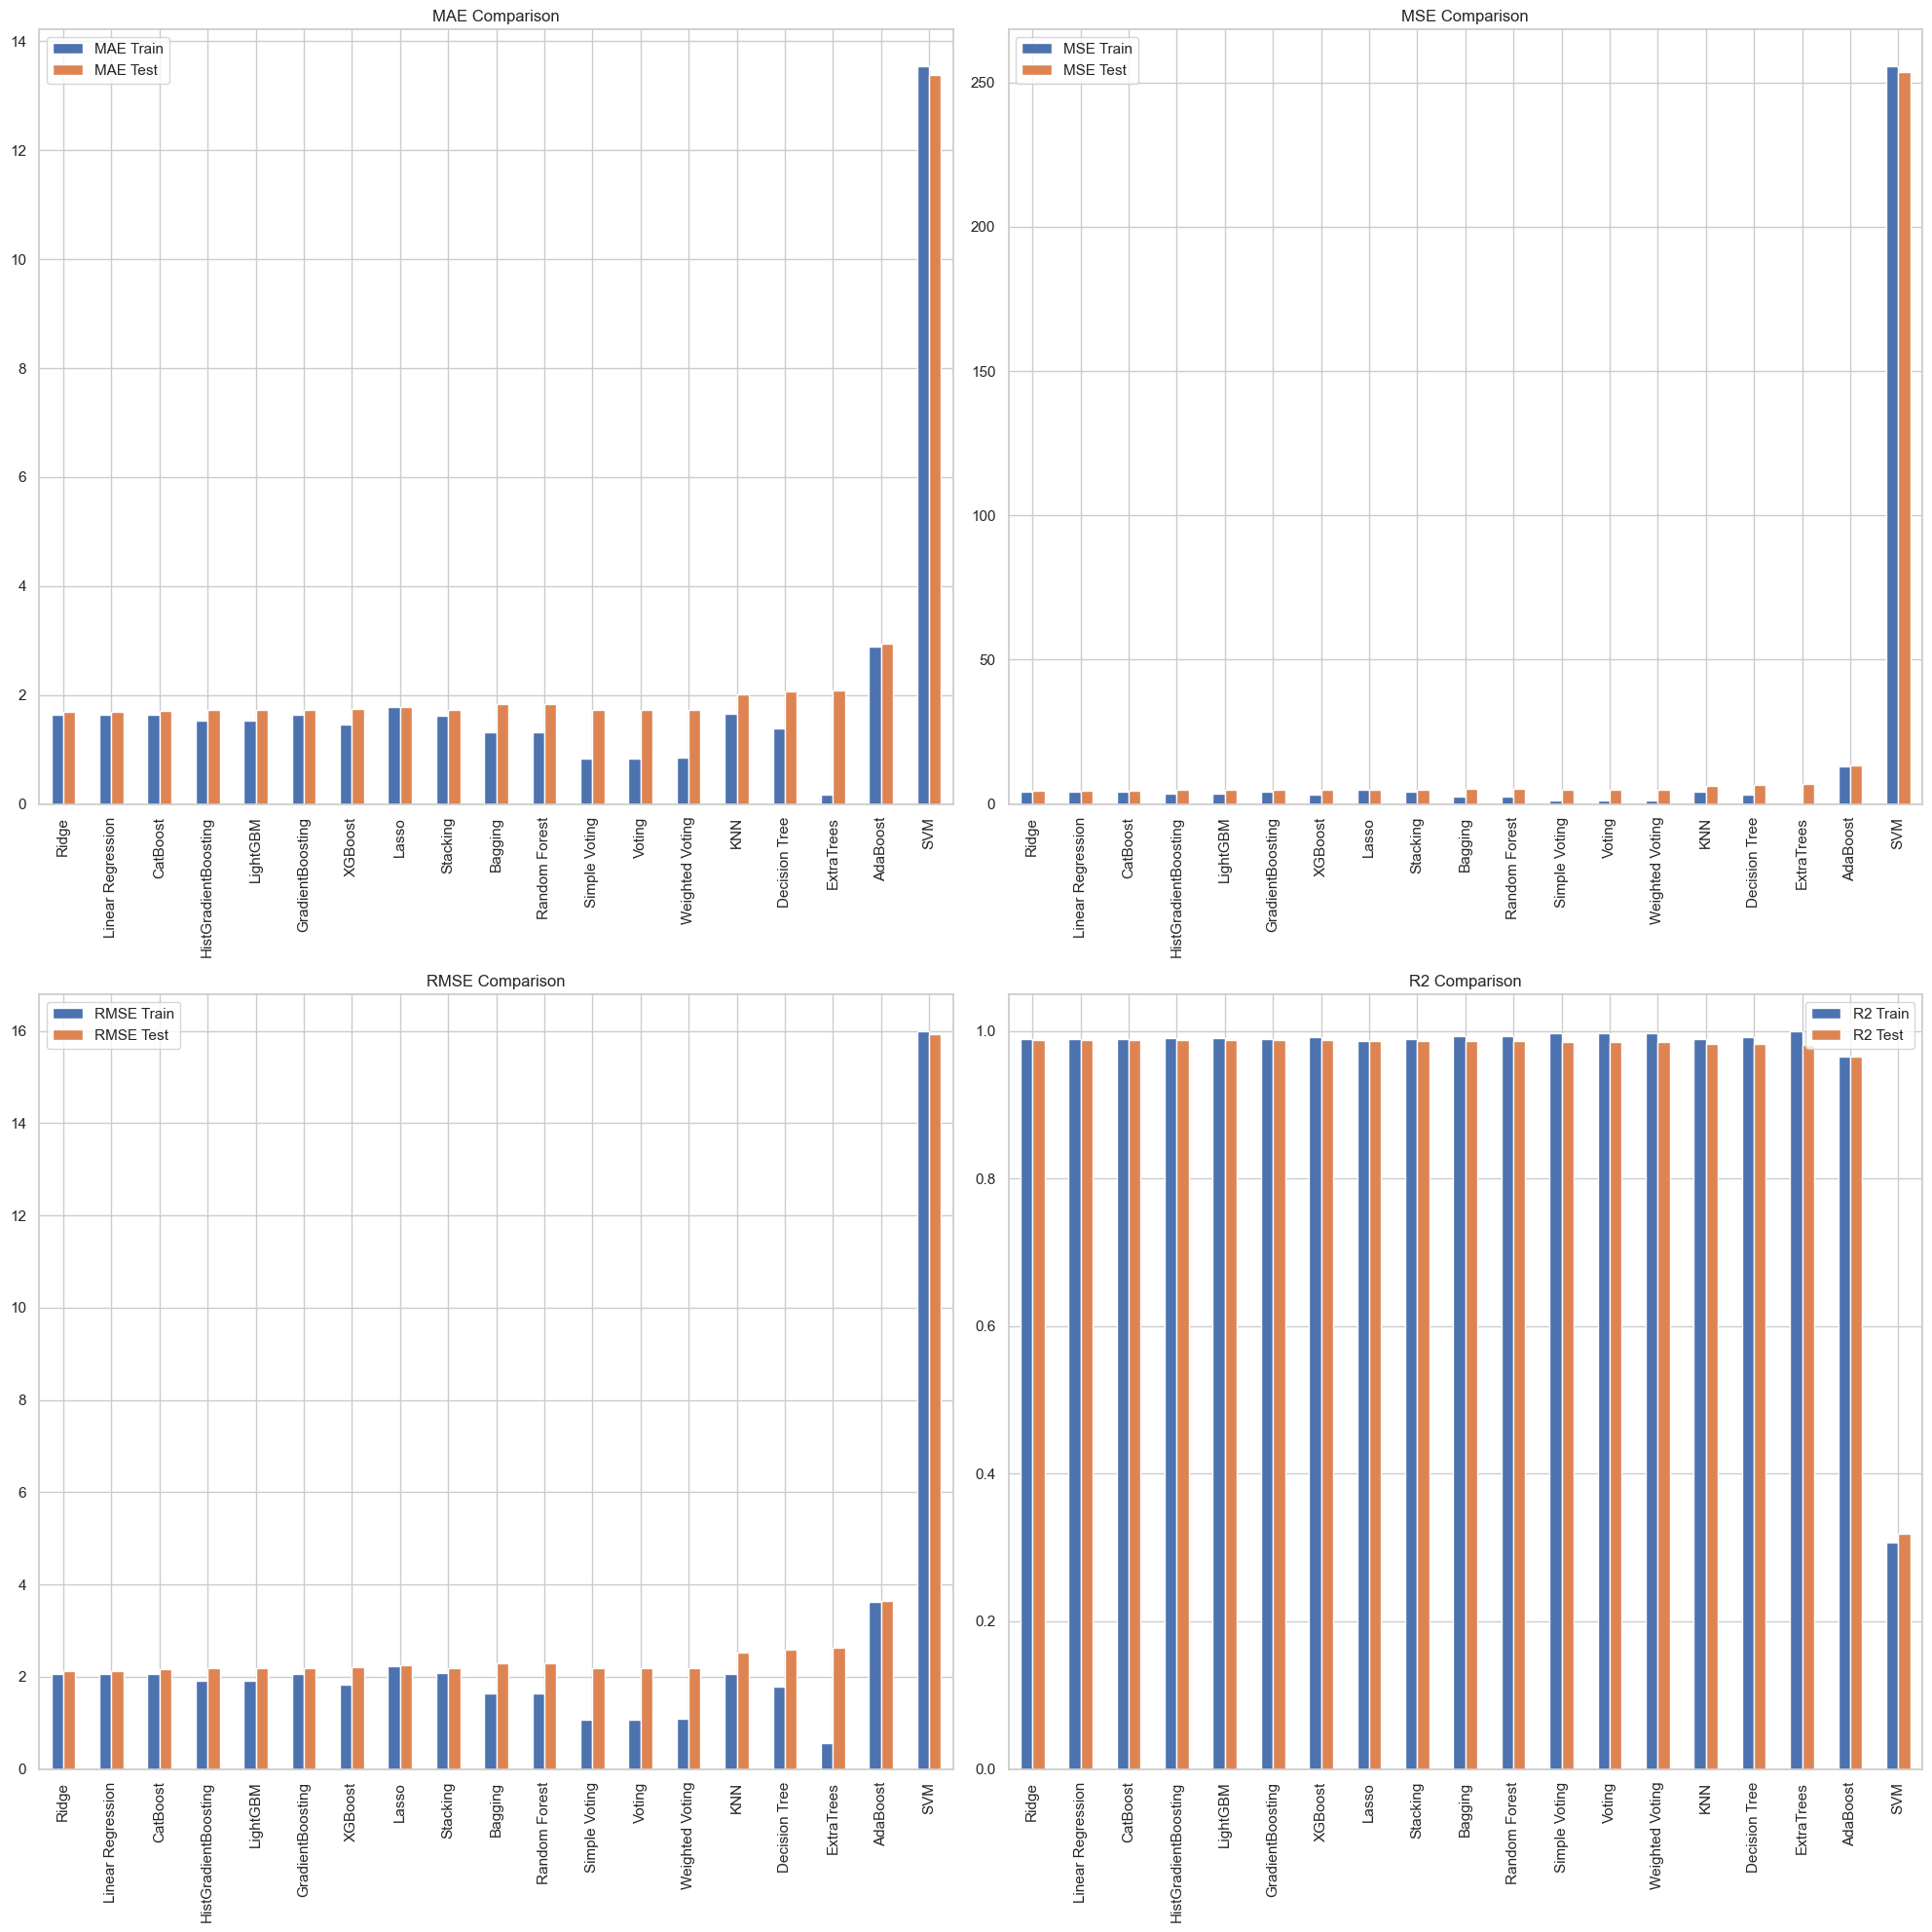

In [30]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()